<a href="https://colab.research.google.com/github/filarancesonia/filarancesonia/blob/main/Soniya_Filarance_M_Final_main_Project_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Libraries imported successfully")

Libraries imported successfully


In [2]:
df = pd.read_csv("student_performance.csv")
print("Dataset loaded successfully")
print(df.head())

Dataset loaded successfully
   Study Hours  Attendance  Previous Marks  Final Marks Result
0            2          60              45           48   Fail
1            3          65              50           52   Pass
2            5          75              60           65   Pass
3            1          40              30           35   Fail
4            6          85              70           78   Pass


In [3]:
print("Dataset Shape:")
print(df.shape)
print("\nColumn Names:")
print(df.columns)
print("\nDataset Information:")
print(df.info())
print("\nStatistical Summary:")
print(df.describe())
print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape:
(12, 5)

Column Names:
Index(['Study Hours', 'Attendance', 'Previous Marks', 'Final Marks', 'Result'], dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Study Hours     12 non-null     int64 
 1   Attendance      12 non-null     int64 
 2   Previous Marks  12 non-null     int64 
 3   Final Marks     12 non-null     int64 
 4   Result          12 non-null     object
dtypes: int64(4), object(1)
memory usage: 612.0+ bytes
None

Statistical Summary:
       Study Hours  Attendance  Previous Marks  Final Marks
count    12.000000   12.000000       12.000000    12.000000
mean      3.916667   66.666667       53.333333    58.750000
std       2.314316   19.345346       19.345346    20.538766
min       1.000000   35.000000       25.000000    30.000000
25%       2.000000   53.750000       38.750000    43

In [4]:
print("Missing Values Before Cleaning:")
print(df.isnull().sum())

df = df.drop_duplicates()

print("\nDuplicate Records Removed")

print("\nFinal Dataset Shape:")
print(df.shape)

Missing Values Before Cleaning:
Study Hours       0
Attendance        0
Previous Marks    0
Final Marks       0
Result            0
dtype: int64

Duplicate Records Removed

Final Dataset Shape:
(12, 5)


In [5]:
X = df[["Study Hours", "Attendance", "Previous Marks"]]

y = df["Final Marks"]

print("Input Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

print("\nX Shape:", X.shape)
print("y Shape:", y.shape)

Input Features:
   Study Hours  Attendance  Previous Marks
0            2          60              45
1            3          65              50
2            5          75              60
3            1          40              30
4            6          85              70

Target Variable:
0    48
1    52
2    65
3    35
4    78
Name: Final Marks, dtype: int64

X Shape: (12, 3)
y Shape: (12,)


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (9, 3)
Testing Data: (3, 3)


In [7]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully")

Linear Regression Model Trained Successfully


In [8]:
y_pred = model.predict(X_test)

print("Actual Marks:")
print(y_test.values)

print("\nPredicted Marks:")
print(y_pred)

Actual Marks:
[72 92 48]

Predicted Marks:
[69.93412162 94.80067568 46.70101351]


In [9]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Regression Model Evaluation")

print("MAE:", mae)

print("MSE:", mse)

print("RMSE:", rmse)

print("R2 Score:", r2)

Regression Model Evaluation
MAE: 2.055180180180185
MSE: 4.599667868882413
RMSE: 2.1446836290890117
R2 Score: 0.9857839935371079


In [10]:
new_student = pd.DataFrame({
    "Study Hours": [5],
    "Attendance": [80],
    "Previous Marks": [65]
})

predicted_marks = model.predict(new_student)

print("New Student Details:")
print(new_student)

print("\nPredicted Final Marks:")
print(round(predicted_marks[0], 2))

New Student Details:
   Study Hours  Attendance  Previous Marks
0            5          80              65

Predicted Final Marks:
69.93


In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Classification Libraries Imported Successfully")

Classification Libraries Imported Successfully


In [12]:
X_class = df[["Study Hours", "Attendance", "Previous Marks"]]

y_class = df["Result"].map({
    "Fail": 0,
    "Pass": 1
})

print("Input Features:")
print(X_class.head())

print("\nTarget Values:")
print(y_class)

Input Features:
   Study Hours  Attendance  Previous Marks
0            2          60              45
1            3          65              50
2            5          75              60
3            1          40              30
4            6          85              70

Target Values:
0     0
1     1
2     1
3     0
4     1
5     1
6     0
7     1
8     0
9     1
10    1
11    0
Name: Result, dtype: int64


In [13]:
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_class,
    y_class,
    test_size=0.25,
    random_state=42,
    stratify=y_class
)

print("Training Data:", X_train_c.shape)
print("Testing Data:", X_test_c.shape)

Training Data: (9, 3)
Testing Data: (3, 3)


In [14]:
log_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

log_model.fit(X_train_c, y_train_c)

print("Logistic Regression Model Trained Successfully")

Logistic Regression Model Trained Successfully


In [15]:
y_pred_c = log_model.predict(X_test_c)

print("Actual Results:")

print(y_test_c.values)

print("\nPredicted Results:")

print(y_pred_c)

result_labels = []

for value in y_pred_c:

    result_labels.append({0: "Fail", 1: "Pass"}[value])

print("\nPredicted Student Results:")

print(result_labels)

Actual Results:
[0 1 1]

Predicted Results:
[0 1 1]

Predicted Student Results:
['Fail', 'Pass', 'Pass']


In [16]:
accuracy = accuracy_score(y_test_c, y_pred_c)

precision = precision_score(
    y_test_c, y_pred_c, zero_division=0
)

recall = recall_score(
    y_test_c, y_pred_c, zero_division=0
)

f1 = f1_score(
    y_test_c, y_pred_c, zero_division=0
)

print("Classification Model Evaluation")

print("Accuracy:", accuracy)

print("Precision:", precision)

print("Recall:", recall)

print("F1 Score:", f1)

Classification Model Evaluation
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


In [17]:
cm = confusion_matrix(y_test_c, y_pred_c)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[1 0]
 [0 2]]


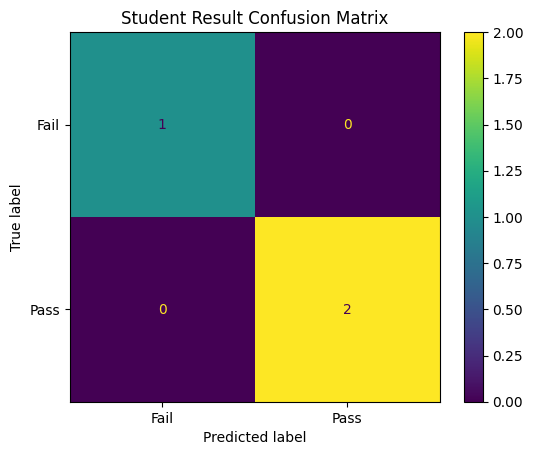

In [18]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test_c,
    y_pred_c,
    display_labels=["Fail", "Pass"]
)

plt.title("Student Result Confusion Matrix")

plt.show()

In [20]:
new_student_c = pd.DataFrame({
    "Study Hours": [5],
    "Attendance": [80],
    "Previous Marks": [65]
})

predicted_result = log_model.predict(new_student_c)

result = {0: "Fail", 1: "Pass"}[predicted_result[0]]

print("Predicted Result:", result)

Predicted Result: Pass


In [21]:
comparison = pd.DataFrame({
    "Comparison": [
        "Algorithm",
        "Target Variable",
        "Prediction Type",
        "Evaluation Metrics",
        "Application"
    ],

    "Regression": [
        "Linear Regression",
        "Final Marks",
        "Numerical Prediction",
        "MAE, MSE, RMSE, R2",
        "Predict Student Marks"
    ],

    "Classification": [
        "Logistic Regression",
        "Result",
        "Pass or Fail",
        "Accuracy, Precision, Recall, F1",
        "Predict Student Result"
    ]
})

print(comparison)

           Comparison             Regression                   Classification
0           Algorithm      Linear Regression              Logistic Regression
1     Target Variable            Final Marks                           Result
2     Prediction Type   Numerical Prediction                     Pass or Fail
3  Evaluation Metrics     MAE, MSE, RMSE, R2  Accuracy, Precision, Recall, F1
4         Application  Predict Student Marks           Predict Student Result


In [22]:
import pandas as pd

print("======================================")
print("  STUDENT PERFORMANCE PREDICTION")
print("======================================")


study_hours = float(input("Enter Study Hours: "))
attendance = float(input("Enter Attendance (%): "))
previous_marks = float(input("Enter Previous Marks: "))


student_data = pd.DataFrame({
    "Study Hours": [study_hours],
    "Attendance": [attendance],
    "Previous Marks": [previous_marks]
})


predicted_marks = model.predict(student_data)


predicted_result = log_model.predict(student_data)

result = {0: "FAIL", 1: "PASS"}[int(predicted_result[0])]


print("\n========== FINAL PREDICTION ==========")

print("Study Hours:", study_hours)
print("Attendance:", attendance, "%")
print("Previous Marks:", previous_marks)

print("\n--- REGRESSION OUTPUT ---")
print("Expected Final Marks:", round(predicted_marks[0], 2))

print("\n--- CLASSIFICATION OUTPUT ---")
print("Predicted Student Result:", result)

print("\n======================================")
print("       PREDICTION COMPLETED")
print("======================================")

  STUDENT PERFORMANCE PREDICTION
Enter Study Hours: 3
Enter Attendance (%): 80
Enter Previous Marks: 90

========== FINAL PREDICTION ==========
Study Hours: 3.0
Attendance: 80.0 %
Previous Marks: 90.0

--- REGRESSION OUTPUT ---
Expected Final Marks: 91.82

--- CLASSIFICATION OUTPUT ---
Predicted Student Result: PASS

       PREDICTION COMPLETED






| Comparison | Regression Model | Classification Model |
|---|---|---|
| **Algorithm Used** | Linear Regression | Logistic Regression |
| **Target Variable** | Final Marks | Result (Pass/Fail) |
| **Type of Prediction** | Predicts numerical values, such as expected final marks. | Predicts categories, such as Pass or Fail. |
| **Evaluation Metrics** | MAE, MSE, RMSE and R² Score. | Accuracy, Precision, Recall, F1-Score and Confusion Matrix. |
| **Real-World Application** | Used to estimate students' expected marks based on their study hours, attendance and previous marks. | Used to identify whether a student is likely to pass or fail based on their performance details. |

